In [ ]:
# Loading Geographic Data and Defining the Study Area:
# - Uses GeoPandas to load Iran's geographical boundary from a GeoJSON shapefile.
# - Defines the spatial extent of the study area (25–40°N and 44–64°E) and creates a regular grid with a spatial resolution of 0.05°.
# Defining the Visualization Settings:
# - Creates a custom blue-to-red colormap to represent different NO₂ column values.
# - Sets a fixed color range from 0 to \(2.5 \times 10^{-4}\) mol/m² to ensure consistency between maps.
# Processing Sentinel-5P/TROPOMI Data:
# - Uses the NetCDF4 library and Glob to identify and read all .nc files in the specified directory.
# - Extracts the following variables from the PRODUCT group:
 # - Latitude and longitude coordinates.
 # - nitrogendioxide_tropospheric_column (tropospheric NO₂ vertical column density).
# - Flattens the spatial arrays and removes records containing missing NO₂ values.
# - Assigns each valid observation to the corresponding grid cell and accumulates NO₂ values and observation counts.
# Calculating Mean NO₂ Values:
# - Calculates the mean NO₂ column density for each grid cell by dividing the accumulated values by the number of observations.
# - Uses the Iran geographical boundary to retain only grid cells located within the country's borders.
# Spatial Gap Filling and Smoothing:
# - Applies a neighborhood-based filtering method (generic_filter) to fill missing grid cells using the mean of their neighboring values.
# - Produces a more spatially continuous representation of the NO₂ distribution.
# Generating and Saving the Map:
# - Uses Cartopy and Matplotlib to generate a spatial map of mean tropospheric NO₂ column density over Iran.
# - Displays Iran's boundaries, coastlines, and a vertical color bar with scientific notation.
# - Saves the final map as a high-resolution PNG image (mean_no2_map_smooth.png) at 300 DPI.

در حال پردازش: S5P_OFFL_L2__NO2____20240901T081912_20240901T100042_35681_03_020600_20240903T002522.nc


C:\Users\intel\AppData\Local\Temp\ipykernel_5232\1485514839.py:81: UserWarning: Warning: converting a masked element to nan.
  grid_sum[lat_idx, lon_idx] += value


در حال پردازش: S5P_OFFL_L2__NO2____20240905T084405_20240905T102535_35738_03_020600_20240907T005238.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240910T085002_20240910T103132_35809_03_020701_20240913T010905.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240915T085556_20240915T103726_35880_03_020701_20240917T040432.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240920T090148_20240920T104318_35951_03_020701_20240922T010025.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240925T072610_20240925T090739_36021_03_020701_20240926T231827.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240930T073159_20240930T091328_36092_03_020701_20241004T231757.nc
در حال پردازش: S5P_OFFL_L2__NO2____20240930T091328_20240930T105458_36093_03_020701_20241005T012824.nc
در حال پردازش: S5P_OFFL_L2__NO2____20241001T085420_20241001T103550_36107_03_020701_20241005T214946.nc
در حال پردازش: S5P_OFFL_L2__NO2____20241005T073746_20241005T091916_36163_03_020701_20241009T024048.nc
در حال پردازش: S5P_OFFL_L2__NO2____20241005T091916_20241005T110045_36164_03_020701

C:\Users\intel\AppData\Local\Temp\ipykernel_5232\1485514839.py:91: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  within_iran = points_gdf.within(iran.unary_union)
C:\ProgramData\anaconda3\Lib\site-packages\scipy\ndimage\_filters.py:1856: RuntimeWarning: Mean of empty slice
  _nd_image.generic_filter(input, function, footprint, output, mode,
C:\Users\intel\AppData\Local\Temp\ipykernel_5232\1485514839.py:122: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  [iran.unary_union],


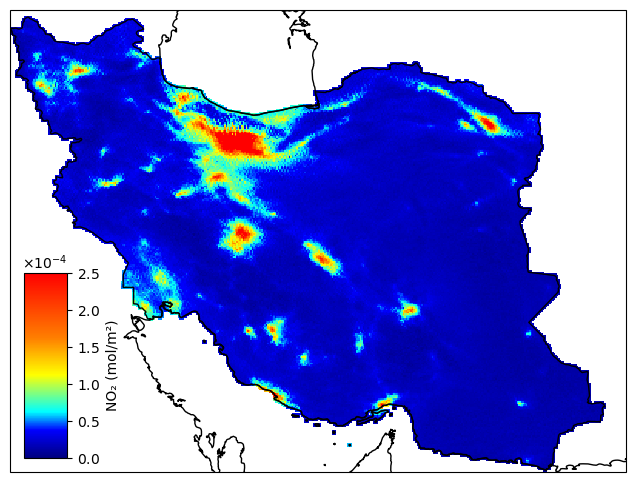

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
from netCDF4 import Dataset
import os
import glob
from shapely.geometry import box, Point
from matplotlib.ticker import ScalarFormatter

# Color Range Determination Function
def auto_color_range(data, upper_percentile=99.5):
    lower = 0
    upper = np.nanpercentile(data, upper_percentile)
    return lower, upper

# Loading Iran shapefile
iran_shapefile = "C:/Users/intel/Documents/ir.json"
iran = gpd.read_file(iran_shapefile)

# Defining a custom colormap
colors = [
    (0.0, '#00007F'),
    (0.15, '#0000FF'),
    (0.25, '#00FFFF'),
    (0.45, '#FFFF00'),
    (0.65, '#FF7F00'),
    (1.0, '#FF0000')
]
custom_cmap = LinearSegmentedColormap.from_list("custom_no2", colors)

# Grid Settings
lat_min, lat_max = 25, 40
lon_min, lon_max = 44, 64
grid_res = 0.05  # Grid Resolution (Degree)

# Creating a grid
lat_bins = np.arange(lat_min, lat_max + grid_res, grid_res)
lon_bins = np.arange(lon_min, lon_max + grid_res, grid_res)
lon_grid, lat_grid = np.meshgrid(
    lon_bins[:-1] + grid_res/2,
    lat_bins[:-1] + grid_res/2
)

# Matrix Preparation
grid_sum = np.zeros(lat_grid.shape)
grid_count = np.zeros(lat_grid.shape)

# File Folder Path
folder_path = "C:/Users/intel/Downloads/SON"
file_paths = glob.glob(os.path.join(folder_path, "*.nc"))

# Processing Files
for file_path in file_paths:
    print(f"در حال پردازش: {os.path.basename(file_path)}")
    with Dataset(file_path, mode='r') as nc_file:
        product = nc_file.groups['PRODUCT']
        latitude = product.variables['latitude'][:]
        longitude = product.variables['longitude'][:]
        no2 = product.variables['nitrogendioxide_tropospheric_column'][:]

    # Flattening
    latitudes_flat = latitude.flatten()
    longitudes_flat = longitude.flatten()
    no2_flat = no2.flatten()

    # Removing NaN
    valid_mask = ~np.isnan(no2_flat)
    latitudes_flat = latitudes_flat[valid_mask]
    longitudes_flat = longitudes_flat[valid_mask]
    no2_flat = no2_flat[valid_mask]

    # Snapping to the grid
    lat_indices = np.digitize(latitudes_flat, lat_bins) - 1
    lon_indices = np.digitize(longitudes_flat, lon_bins) - 1

    for lat_idx, lon_idx, value in zip(lat_indices, lon_indices, no2_flat):
        if 0 <= lat_idx < grid_sum.shape[0] and 0 <= lon_idx < grid_sum.shape[1]:
            grid_sum[lat_idx, lon_idx] += value
            grid_count[lat_idx, lon_idx] += 1

# Calculating the Average
grid_mean = np.divide(grid_sum, grid_count, out=np.full_like(grid_sum, np.nan), where=grid_count != 0)

# Filter: Only locations within Iran
points = [Point(x, y) for x, y in zip(lon_grid.flatten(), lat_grid.flatten())]
points_gdf = gpd.GeoDataFrame(geometry=points, crs="EPSG:4326")

within_iran = points_gdf.within(iran.unary_union)
within_iran_mask = np.array(within_iran).reshape(lat_grid.shape)

grid_mean_masked = np.where(within_iran_mask, grid_mean, np.nan)  # Only amounts within Iran

# Filling in the gaps to create a continuous map
# Method: Where values are NaN, they are replaced by the mean of their neighbors.
from scipy.ndimage import generic_filter

def fill_nan(arr):
    nan_mask = np.isnan(arr)
    filled = arr.copy()
    filled[nan_mask] = generic_filter(arr, np.nanmean, size=3)[nan_mask]
    return filled

grid_mean_filled = fill_nan(grid_mean_masked)

# Defining the Color Range
#vmin, vmax = auto_color_range(grid_mean_filled)

# Here, we fix vmin and vmax
vmin = 0
vmax = 2.5e-4  # The same maximum value that was used in the previous file

# Drawing
fig = plt.figure(figsize=(10, 6), facecolor='white')
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# Delineating Iran's Borders
ax.add_geometries(
    [iran.unary_union],
    crs=ccrs.PlateCarree(),
    facecolor='none',
    edgecolor='black',
    linewidth=1
)

# Drawing a grid
pcm = ax.pcolormesh(
    lon_bins, lat_bins, grid_mean_filled,
    cmap=custom_cmap,
    vmin=vmin, vmax=vmax,
    shading='auto',
    transform=ccrs.PlateCarree()
)

# Map Features
ax.coastlines()

# Colorbar
cax = inset_axes(ax, width="7%", height="40%", loc='lower left', borderpad=1)
cbar = fig.colorbar(pcm, cax=cax, orientation='vertical')
cbar.set_label("NO₂ (mol/m²)")

cbar.formatter = ScalarFormatter(useMathText=True)
cbar.formatter.set_powerlimits((0, 4))
cbar.update_ticks()

# Save Output
plt.savefig("mean_no2_map_smooth.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()